# Top 10 pairs at motif lengths of 1–61 s

Full `SOCAL_H_76_230427_014845.x_10kHz.wav` (37.5 min at 10 kHz). Motif lengths are 1, 11, 21, 31, 41, 51, and 61 seconds.

The profile is the RMS in non-overlapping 10 ms frames (100 Hz). A pairwise profile of the raw 22.5 million samples is not practical, and these lengths are seconds rather than milliseconds.

`mpx_fast` is called with `minlag` equal to the motif length, so the two starts in a pair are at least one motif length apart. Pairs are ranked by how extreme that correlation is among matches of the same length, so a long motif is not buried just because a 1-second window correlates more easily. A later pair is skipped when it overlaps a pair already chosen.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from scipy.io import wavfile

REPO = Path("/home/yfreund/projects/panMP_whales")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from analysis.matrix_profile import (
    format_clock as clock,
    motif_profile,
    rms_envelope,
    top_pairs_by_zscore,
)

WAV = Path.home() / "whale_processing/LeiData/SOCAL_H_76_230427_014845.x_10kHz.wav"
ENV_RATE = 100
LENGTHS_S = list(range(1, 62, 10))
N_PAIRS = 10

rate, pcm = wavfile.read(WAV)
envelope = rms_envelope(pcm, rate, ENV_RATE)
print(
    f"{WAV.name}  {rate} Hz  {len(pcm) / rate / 60:.2f} min  "
    f"envelope {len(envelope)} samples at {ENV_RATE} Hz"
)
print("motif lengths (s):", LENGTHS_S)

profiles = {}
for length_s in LENGTHS_S:
    window = length_s * ENV_RATE
    correlation, neighbor = motif_profile(envelope, window, nthreads=8)
    profiles[length_s] = (correlation, neighbor, window)
    print(f"  {length_s:2d} s done", flush=True)

pairs = top_pairs_by_zscore(profiles, N_PAIRS)
print(f"{len(pairs)} pairs")


SOCAL_H_76_230427_014845.x_10kHz.wav  10000 Hz  37.50 min  envelope 225000 samples at 100 Hz
motif lengths (s): [1, 11, 21, 31, 41, 51, 61]


   1 s done


  11 s done


  21 s done


  31 s done


  41 s done


  51 s done


  61 s done


10 pairs


## Times

Time A and time B are the starts of the two copies. Separation is at least the motif length. Correlation is the z-normalized match (1 is identical). The z column is how far that correlation sits above the mean match of the same length.

In [2]:
lines = [
    "| rank | length (s) | time A | time B | separation (s) | correlation | z |",
    "|---:|---:|---:|---:|---:|---:|---:|",
]
for rank, (length_s, i, j, corr, unusual) in enumerate(pairs, start=1):
    t_a = i / ENV_RATE
    t_b = j / ENV_RATE
    lines.append(
        f"| {rank} | {length_s} | {clock(t_a)} | {clock(t_b)} | {t_b - t_a:.1f} | {corr:.3f} | {unusual:.1f} |"
    )
display(Markdown("\n".join(lines)))

best_lines = [
    "### Best pair at each length",
    "",
    "| length (s) | time A | time B | separation (s) | correlation |",
    "|---:|---:|---:|---:|---:|",
]
for length_s in LENGTHS_S:
    corr, neighbor, window = profiles[length_s]
    i = int(np.nanargmax(corr))
    j = int(neighbor[i])
    if j < i:
        i, j = j, i
    t_a, t_b = i / ENV_RATE, j / ENV_RATE
    best_lines.append(
        f"| {length_s} | {clock(t_a)} | {clock(t_b)} | {t_b - t_a:.1f} | {corr[i]:.3f} |"
    )
display(Markdown("\n".join(best_lines)))


| rank | length (s) | time A | time B | separation (s) | correlation | z |
|---:|---:|---:|---:|---:|---:|---:|
| 1 | 1 | 15:26.3 | 16:33.7 | 67.3 | 0.857 | 5.5 |
| 2 | 1 | 15:25.5 | 15:35.0 | 9.5 | 0.839 | 5.2 |
| 3 | 1 | 16:33.5 | 16:47.7 | 14.2 | 0.830 | 5.0 |
| 4 | 1 | 15:35.3 | 17:16.8 | 101.5 | 0.829 | 5.0 |
| 5 | 1 | 9:52.6 | 10:04.0 | 11.4 | 0.822 | 4.9 |
| 6 | 1 | 34:05.7 | 34:29.1 | 23.5 | 0.817 | 4.8 |
| 7 | 1 | 16:46.8 | 17:32.1 | 45.3 | 0.816 | 4.8 |
| 8 | 1 | 9:11.1 | 9:13.4 | 2.3 | 0.803 | 4.5 |
| 9 | 1 | 9:30.2 | 9:42.4 | 12.1 | 0.798 | 4.4 |
| 10 | 1 | 11:26.3 | 12:00.7 | 34.4 | 0.787 | 4.2 |

### Best pair at each length

| length (s) | time A | time B | separation (s) | correlation |
|---:|---:|---:|---:|---:|
| 1 | 15:26.3 | 16:33.7 | 67.3 | 0.857 |
| 11 | 11:14.9 | 11:49.3 | 34.5 | 0.458 |
| 21 | 11:05.5 | 11:40.0 | 34.5 | 0.389 |
| 31 | 11:04.0 | 11:38.5 | 34.5 | 0.330 |
| 41 | 9:37.7 | 11:10.6 | 92.9 | 0.268 |
| 51 | 9:32.5 | 11:05.4 | 92.9 | 0.248 |
| 61 | 9:57.6 | 11:42.2 | 104.6 | 0.218 |

## Where they sit

Each color is one pair. The two shaded spans are the two copies.

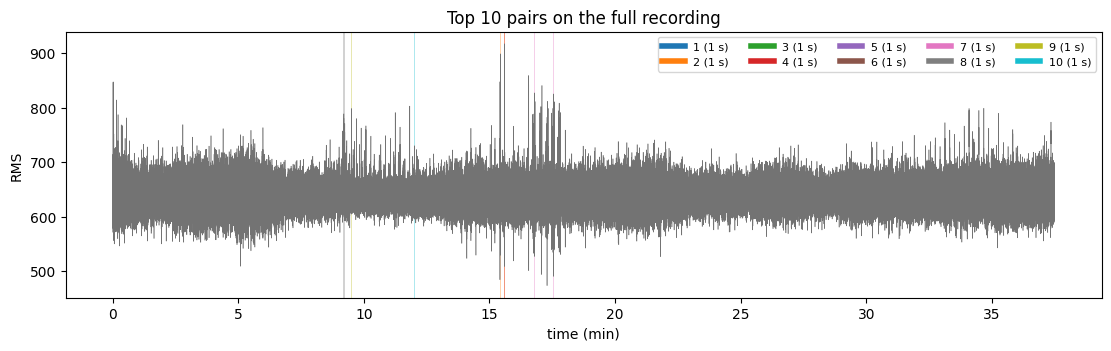

In [3]:
colors = plt.cm.tab10(np.arange(len(pairs)))
time = np.arange(len(envelope)) / ENV_RATE / 60.0
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
ax.plot(time, envelope, color="0.45", lw=0.4)
for rank, ((length_s, i, j, _corr, _unusual), color) in enumerate(zip(pairs, colors), start=1):
    for start in (i, j):
        ax.axvspan(
            start / ENV_RATE / 60.0,
            (start + length_s * ENV_RATE) / ENV_RATE / 60.0,
            color=color,
            alpha=0.35,
            lw=0,
        )
    ax.plot([], [], color=color, lw=4, label=f"{rank} ({length_s} s)")
ax.set_xlabel("time (min)")
ax.set_ylabel("RMS")
ax.set_title("Top 10 pairs on the full recording")
ax.legend(ncol=5, fontsize=8)
plt.show()


## The ten pairs

Each panel is the two RMS envelopes, z-scored. The legend is the start time of each copy.

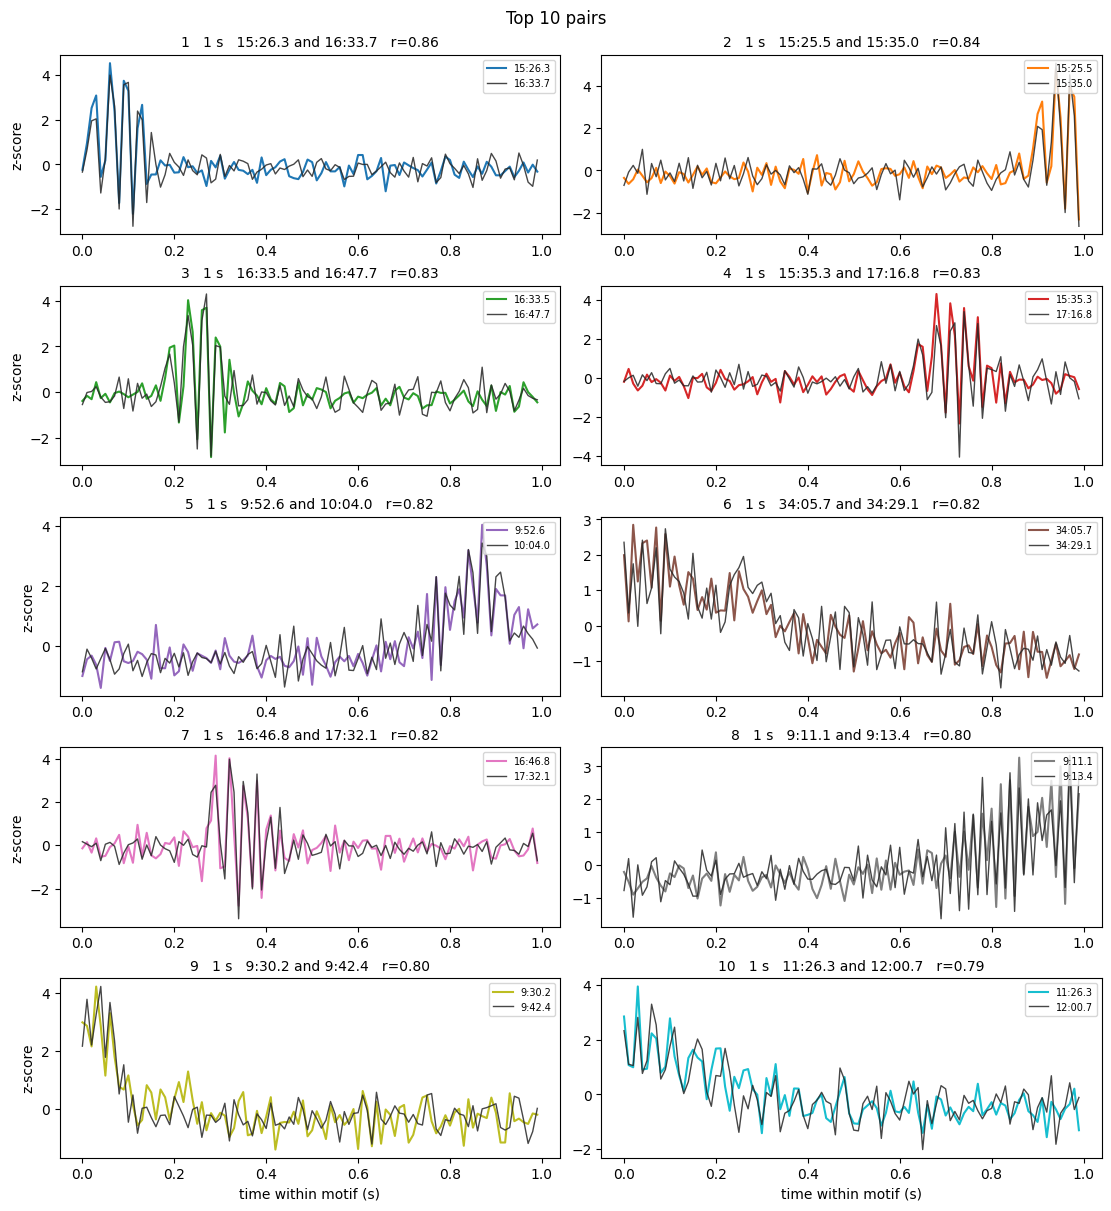

In [4]:
def zscore(window):
    window = np.asarray(window, dtype=np.float64)
    return (window - window.mean()) / (window.std() + 1e-12)

fig, axes = plt.subplots(5, 2, figsize=(11, 12), layout="constrained")
for ax, (rank, (length_s, i, j, corr, _unusual), color) in zip(
    axes.ravel(), ((n, pair, c) for n, (pair, c) in enumerate(zip(pairs, colors), start=1))
):
    window = length_s * ENV_RATE
    within = np.arange(window) / ENV_RATE
    ax.plot(within, zscore(envelope[i : i + window]), color=color, label=clock(i / ENV_RATE))
    ax.plot(
        within,
        zscore(envelope[j : j + window]),
        color="0.15",
        lw=1.0,
        alpha=0.85,
        label=clock(j / ENV_RATE),
    )
    ax.set_title(
        f"{rank}   {length_s} s   {clock(i / ENV_RATE)} and {clock(j / ENV_RATE)}   r={corr:.2f}",
        fontsize=10,
    )
    ax.legend(fontsize=7, loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("time within motif (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("z-score")
fig.suptitle("Top 10 pairs")
plt.show()
